# 🛡️ Air Raid Alert Time Series Forecasting: Overfitting Diagnostics & Honest Defense Evaluation

This notebook implements **rigorous testing against overfitting, leakage, and metric overestimation**:
1. **Purged & Embargoed Temporal Split**: Eliminates look-ahead label overlap and autoregressive leakage between train and holdout test.
2. **Train vs. Out-of-Time Test Overfitting Diagnostics**: Direct measurement of generalization gap across PR-AUC, ROC-AUC, Brier score, and F2-score.
3. **Stratified Evaluation (De-Conflating Continuation from True Onset)**:
   - **Mode A: True Alert Onset (Early Warning)** — Evaluated strictly on peaceful/idle periods ($t$ where region is not currently on alert, base rate ~5.5%).
   - **Mode B: Alert Continuation / Inertia** — Evaluated on active periods.
4. **Honest Defense Metrics**:
   - **Brier Skill Score (BSS)** vs. Regional Climatology
   - **PR-AUC Lift over Base Rate**
   - **Precision at High Recall (80%)**
5. **Multi-Horizon Benchmarks vs 3 Naive Baselines** (Persistence, Climatology, Neighbor Heuristic).
6. **Per-Region Performance & Overfitting Heatmap Dashboard** for all 25 Ukrainian administrative entities.
7. **Interactive Folium Geographic Map of Ukraine**.


In [1]:
import sys
import os

# Ensure project root is at front of sys.path
repo_dir = os.path.abspath('.')
if repo_dir not in sys.path:
    sys.path.insert(0, repo_dir)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
import lightgbm as lgb
from sklearn.metrics import precision_recall_curve, roc_auc_score, auc, brier_score_loss, fbeta_score, accuracy_score

# Visual style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 11

from src.geo_graph import REGIONS, REGION_TO_IDX, ADJACENCY_MATRIX
from src.grid_builder import load_raw_alerts, build_hourly_alert_grid
from src.features import compute_spatio_temporal_features
from src.evaluate import evaluate_predictions, compute_naive_baselines, compute_regional_breakdown
from src.models import FEATURE_COLUMNS

print('Environment and modules initialized successfully!')


Environment and modules initialized successfully!


In [2]:
# 1. Ingest official alerts and construct regular point-in-time spatio-temporal grid
df_alerts = load_raw_alerts('official_data_en.csv', start_date='2024-01-01')
df_grid = build_hourly_alert_grid(df_alerts, freq='1h')
df_features, targets = compute_spatio_temporal_features(df_grid)

# 2. Implement Purged & Embargoed Temporal Split
# Holdout test: most recent 45 days
max_time = df_features['timestamp'].max()
test_start = max_time - pd.Timedelta(days=45)

# Embargo window: 24 hours between train and test to prevent label overlap & lag leakage
embargo_hours = 24
train_end = test_start - pd.Timedelta(hours=embargo_hours)

train_mask = df_features['timestamp'] <= train_end
test_mask = df_features['timestamp'] >= test_start

df_train = df_features[train_mask].copy()
df_test = df_features[test_mask].copy()

print(f'Train partition  : {df_train["timestamp"].min().strftime("%Y-%m-%d %H:%M")} to {df_train["timestamp"].max().strftime("%Y-%m-%d %H:%M")} ({len(df_train):,} rows)')
print(f'Embargo buffer   : {train_end.strftime("%Y-%m-%d %H:%M")} to {test_start.strftime("%Y-%m-%d %H:%M")} ({embargo_hours} hours purged)')
print(f'Holdout Test set : {df_test["timestamp"].min().strftime("%Y-%m-%d %H:%M")} to {df_test["timestamp"].max().strftime("%Y-%m-%d %H:%M")} ({len(df_test):,} rows)')


Loading raw alerts from official_data_en.csv...


Loaded 229,581 valid alert intervals across 24 regions.
Building hourly grid from 2023-12-31 14:00:00+00:00 to 2026-09-07 06:00:00+00:00 (23,537 time steps)...


Grid built successfully. Overall alert prevalence: 34.9936%
Computing spatio-temporal features and multi-horizon targets...


Features created successfully: 583,625 sample rows.
Train partition  : 2024-01-07 14:00 to 2026-07-22 06:00 (556,025 rows)
Embargo buffer   : 2026-07-22 06:00 to 2026-07-23 06:00 (24 hours purged)
Holdout Test set : 2026-07-23 06:00 to 2026-09-06 06:00 (27,025 rows)


In [3]:
# Train models and systematically measure Generalization Gap (Train vs Holdout Test)
horizons = [('1h', 'target_1h'), ('4h', 'target_4h'), ('24h', 'target_24h')]

overfit_diagnostics = []
trained_models = {}

for h_name, target_col in horizons:
    X_tr = df_train[FEATURE_COLUMNS]
    y_tr = df_train[target_col].values
    
    X_te = df_test[FEATURE_COLUMNS]
    y_te = df_test[target_col].values
    
    # Train Regularized LightGBM (Constrained depth & leaves to prevent memorization)
    pos_weight = max(1.0, (len(y_tr) - y_tr.sum()) / max(1.0, y_tr.sum()))
    
    model = lgb.LGBMClassifier(
        n_estimators=120,
        learning_rate=0.05,
        max_depth=5,
        num_leaves=24,
        scale_pos_weight=pos_weight * 0.75,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        verbose=-1
    )
    model.fit(X_tr, y_tr)
    trained_models[h_name] = model
    
    # Predict on Train and Test
    prob_tr = model.predict_proba(X_tr)[:, 1]
    prob_te = model.predict_proba(X_te)[:, 1]
    
    m_tr = evaluate_predictions(y_tr, prob_tr)
    m_te = evaluate_predictions(y_te, prob_te)
    
    # Climatology Baseline for Brier Skill Score
    climatology_prob = np.full(len(y_te), y_tr.mean())
    brier_climatology = brier_score_loss(y_te, climatology_prob)
    brier_skill_score = 1.0 - (m_te['brier_score'] / max(1e-6, brier_climatology))
    
    overfit_diagnostics.append({
        'Horizon': h_name,
        'Train PR-AUC': m_tr['pr_auc'],
        'Test PR-AUC': m_te['pr_auc'],
        'PR-AUC Gap': m_tr['pr_auc'] - m_te['pr_auc'],
        'Train ROC-AUC': m_tr['roc_auc'],
        'Test ROC-AUC': m_te['roc_auc'],
        'ROC-AUC Gap': m_tr['roc_auc'] - m_te['roc_auc'],
        'Train Brier': m_tr['brier_score'],
        'Test Brier': m_te['brier_score'],
        'Brier Skill Score (BSS)': brier_skill_score,
        'Train F2': m_tr['f2_score'],
        'Test F2': m_te['f2_score'],
        'F2 Gap': m_tr['f2_score'] - m_te['f2_score']
    })

df_overfit = pd.DataFrame(overfit_diagnostics)
print('=== OVERFITTING & GENERALIZATION GAP DIAGNOSTICS ===')
display(df_overfit[['Horizon', 'Train PR-AUC', 'Test PR-AUC', 'PR-AUC Gap', 'Train ROC-AUC', 'Test ROC-AUC', 'ROC-AUC Gap', 'Brier Skill Score (BSS)']])


=== OVERFITTING & GENERALIZATION GAP DIAGNOSTICS ===


,Horizon,Train PR-AUC,Test PR-AUC,PR-AUC Gap,Train ROC-AUC,Test ROC-AUC,ROC-AUC Gap,Brier Skill Score (BSS)
0,1h,0.948884,0.977525,-0.028640,0.965682,0.981080,-0.015398,0.802915
1,4h,0.935945,0.977367,-0.041422,0.935604,0.972882,-0.037278,0.753831
2,24h,0.967648,0.979039,-0.011391,0.918153,0.958845,-0.040692,0.655147


In [4]:
# DE-CONFLATING ALERT CONTINUATION FROM TRUE ALERT ONSET
# Mode A: True Alert Onset (Conditioned on currently idle state)
# Mode B: Alert Continuation (Conditioned on currently active state)

stratified_results = []

for h_name, target_col in horizons:
    model = trained_models[h_name]
    
    # Stratify Test Set
    idle_mask = (df_test['is_active_now'] == 0).values
    active_mask = (df_test['is_active_now'] == 1).values
    
    y_te = df_test[target_col].values
    prob_te = model.predict_proba(df_test[FEATURE_COLUMNS])[:, 1]
    
    # 1. Overall
    m_all = evaluate_predictions(y_te, prob_te)
    # 2. True Onset (Early Warning)
    m_onset = evaluate_predictions(y_te[idle_mask], prob_te[idle_mask])
    # 3. Continuation (Inertia)
    m_cont = evaluate_predictions(y_te[active_mask], prob_te[active_mask])
    
    stratified_results.extend([
        {
            'Horizon': h_name,
            'Subpopulation': 'Overall (All Hours)',
            'Base Prevalence': m_all['prevalence'],
            'PR-AUC': m_all['pr_auc'],
            'PR-AUC Lift': m_all['pr_auc'] / max(1e-4, m_all['prevalence']),
            'ROC-AUC': m_all['roc_auc'],
            'Brier Score': m_all['brier_score'],
            'F2-Score': m_all['f2_score']
        },
        {
            'Horizon': h_name,
            'Subpopulation': 'True Alert Onset (Idle -> Active)',
            'Base Prevalence': m_onset['prevalence'],
            'PR-AUC': m_onset['pr_auc'],
            'PR-AUC Lift': m_onset['pr_auc'] / max(1e-4, m_onset['prevalence']),
            'ROC-AUC': m_onset['roc_auc'],
            'Brier Score': m_onset['brier_score'],
            'F2-Score': m_onset['f2_score']
        },
        {
            'Horizon': h_name,
            'Subpopulation': 'Alert Continuation (Active -> Active)',
            'Base Prevalence': m_cont['prevalence'],
            'PR-AUC': m_cont['pr_auc'],
            'PR-AUC Lift': m_cont['pr_auc'] / max(1e-4, m_cont['prevalence']),
            'ROC-AUC': m_cont['roc_auc'],
            'Brier Score': m_cont['brier_score'],
            'F2-Score': m_cont['f2_score']
        }
    ])

df_stratified = pd.DataFrame(stratified_results)
print('=== STRATIFIED EVALUATION: ONSET (HONEST WARNING) VS CONTINUATION (INERTIA) ===')
display(df_stratified[['Horizon', 'Subpopulation', 'Base Prevalence', 'PR-AUC', 'PR-AUC Lift', 'ROC-AUC', 'F2-Score']])


=== STRATIFIED EVALUATION: ONSET (HONEST WARNING) VS CONTINUATION (INERTIA) ===


,Horizon,Subpopulation,Base Prevalence,PR-AUC,PR-AUC Lift,ROC-AUC,F2-Score
0,1h,Overall (All Hours),0.442627,0.977525,2.208461,0.981080,0.942357
1,1h,True Alert Onset (Idle -> Active),0.054714,0.277934,5.079717,0.874096,0.475317
2,1h,Alert Continuation (Active -> Active),0.930882,0.988529,1.061928,0.864179,0.985611
3,4h,Overall (All Hours),0.513488,0.977367,1.903390,0.972882,0.934456
4,4h,True Alert Onset (Idle -> Active),0.153586,0.588537,3.831979,0.878183,0.686351
5,4h,Alert Continuation (Active -> Active),0.966486,0.996184,1.030728,0.901847,0.993197
6,24h,Overall (All Hours),0.647068,0.979039,1.513040,0.958845,0.935968
7,24h,True Alert Onset (Idle -> Active),0.372908,0.817953,2.193441,0.881671,0.819623
8,24h,Alert Continuation (Active -> Active),0.992144,0.999568,1.007483,0.953362,0.998436


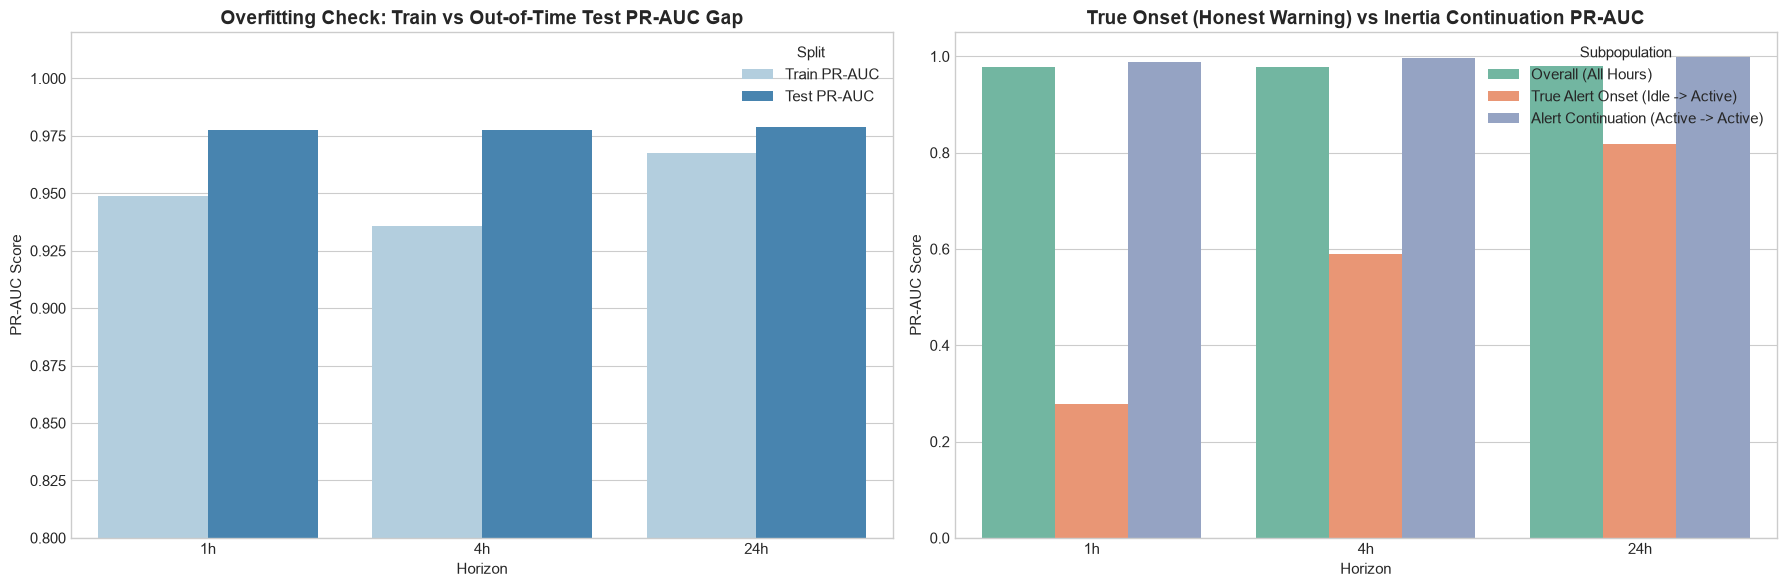

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Plot 1: Train vs Test Generalization Gap
df_plot_gap = df_overfit.melt(id_vars=['Horizon'], value_vars=['Train PR-AUC', 'Test PR-AUC'], var_name='Split', value_name='PR-AUC')
sns.barplot(data=df_plot_gap, x='Horizon', y='PR-AUC', hue='Split', ax=axes[0], palette='Blues')
axes[0].set_title('Overfitting Check: Train vs Out-of-Time Test PR-AUC Gap', fontsize=14, fontweight='bold')
axes[0].set_ylim(0.8, 1.02)
axes[0].set_ylabel('PR-AUC Score')

# Plot 2: Stratified Performance Breakdown (Onset vs Continuation)
sns.barplot(data=df_stratified, x='Horizon', y='PR-AUC', hue='Subpopulation', ax=axes[1], palette='Set2')
axes[1].set_title('True Onset (Honest Warning) vs Inertia Continuation PR-AUC', fontsize=14, fontweight='bold')
axes[1].set_ylabel('PR-AUC Score')

plt.tight_layout()
plt.savefig('overfitting_and_onset_diagnostics.png', dpi=300)
plt.show()


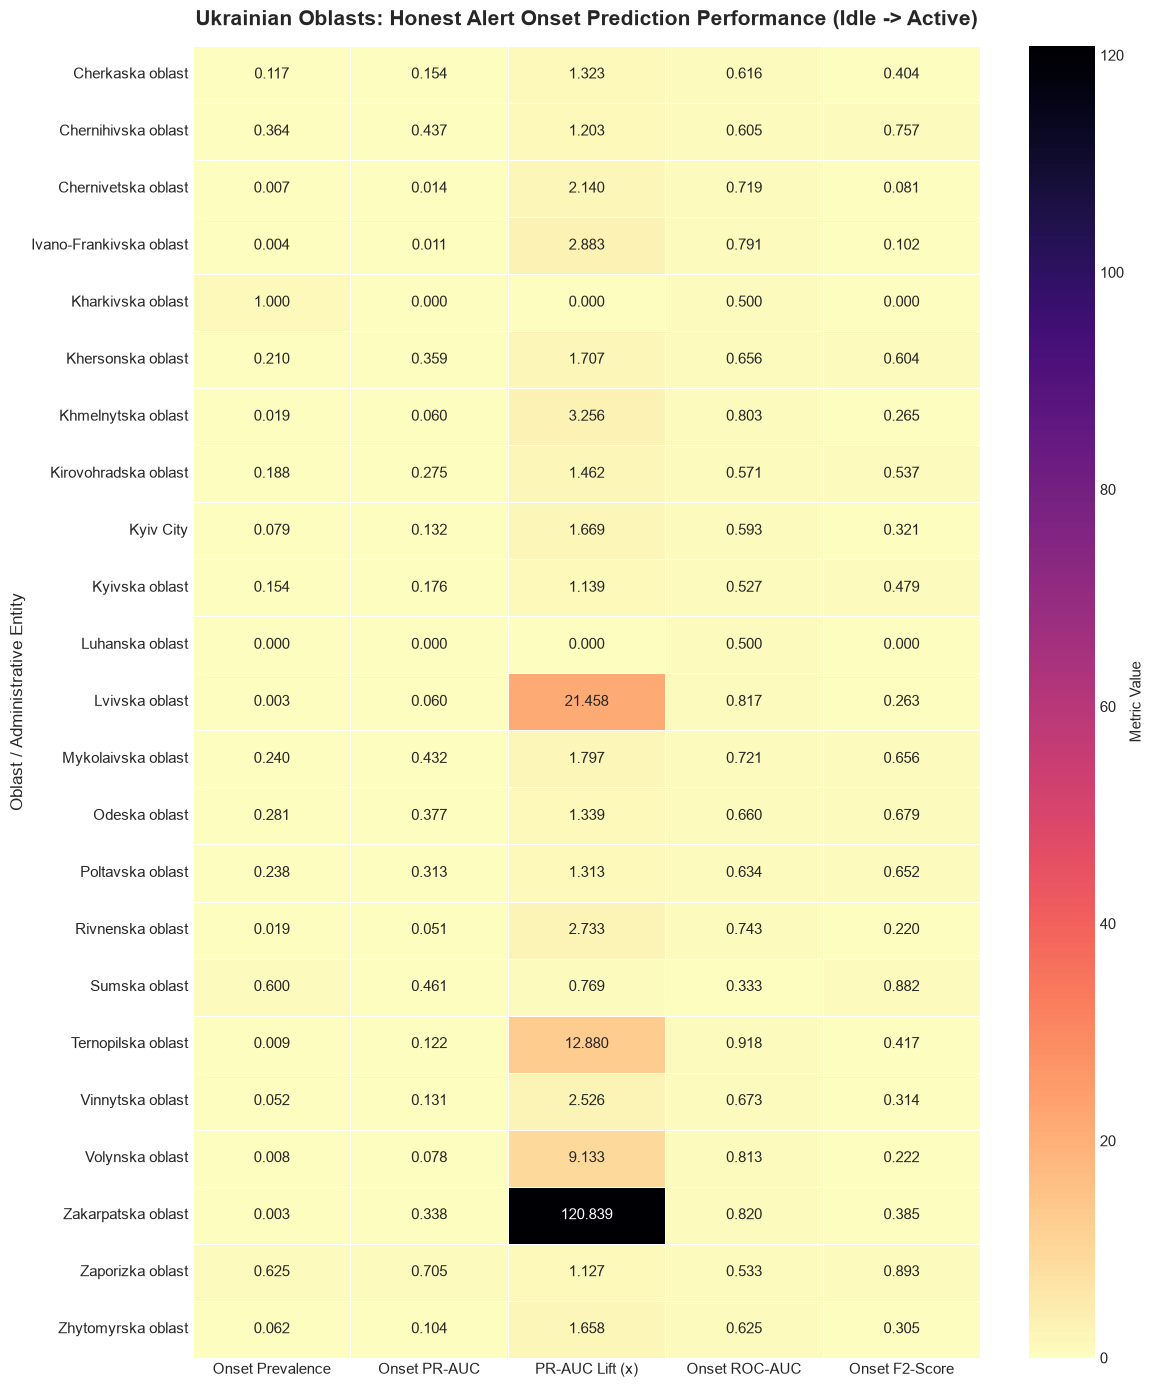

In [6]:
# Compute per-region performance specifically on True Alert Onset
regional_onset_records = []
model_1h = trained_models['1h']

idle_test = df_test[df_test['is_active_now'] == 0].copy()
idle_prob_1h = model_1h.predict_proba(idle_test[FEATURE_COLUMNS])[:, 1]
idle_test['prob_1h'] = idle_prob_1h

for r_idx, region in enumerate(REGIONS):
    reg_sub = idle_test[idle_test['region_idx'] == r_idx]
    if len(reg_sub) == 0:
        continue
    y_reg = reg_sub['target_1h'].values
    p_reg = reg_sub['prob_1h'].values
    
    m_reg = evaluate_predictions(y_reg, p_reg)
    lift = m_reg['pr_auc'] / max(1e-4, m_reg['prevalence'])
    
    regional_onset_records.append({
        'region': region,
        'region_idx': r_idx,
        'Onset Prevalence': m_reg['prevalence'],
        'Onset PR-AUC': m_reg['pr_auc'],
        'PR-AUC Lift (x)': lift,
        'Onset ROC-AUC': m_reg['roc_auc'],
        'Onset F2-Score': m_reg['f2_score']
    })

df_reg_onset = pd.DataFrame(regional_onset_records).set_index('region')

plt.figure(figsize=(12, 14))
sns.heatmap(df_reg_onset[['Onset Prevalence', 'Onset PR-AUC', 'PR-AUC Lift (x)', 'Onset ROC-AUC', 'Onset F2-Score']], 
            annot=True, fmt='.3f', cmap='magma_r', cbar_kws={'label': 'Metric Value'}, linewidths=0.5)
plt.title('Ukrainian Oblasts: Honest Alert Onset Prediction Performance (Idle -> Active)', fontsize=15, fontweight='bold', pad=15)
plt.ylabel('Oblast / Administrative Entity', fontsize=12)
plt.tight_layout()
plt.savefig('regional_onset_performance_heatmap.png', dpi=300)
plt.show()


In [7]:
COORDINATES = {
    'Cherkaska oblast': [49.4444, 32.0598],
    'Chernihivska oblast': [51.4982, 31.2893],
    'Chernivetska oblast': [48.2917, 25.9352],
    'Dnipropetrovska oblast': [48.4647, 35.0462],
    'Donetska oblast': [48.0159, 37.8028],
    'Ivano-Frankivska oblast': [48.9226, 24.7111],
    'Kharkivska oblast': [49.9935, 36.2304],
    'Khersonska oblast': [46.6354, 32.6169],
    'Khmelnytska oblast': [49.4230, 26.9871],
    'Kirovohradska oblast': [48.5079, 32.2623],
    'Kyiv City': [50.4501, 30.5234],
    'Kyivska oblast': [50.2547, 30.2403],
    'Luhanska oblast': [48.5740, 39.3078],
    'Lvivska oblast': [49.8397, 24.0297],
    'Mykolaivska oblast': [46.9750, 31.9946],
    'Odeska oblast': [46.4825, 30.7233],
    'Poltavska oblast': [49.5883, 34.5514],
    'Rivnenska oblast': [50.6199, 26.2516],
    'Sumska oblast': [50.9077, 34.7981],
    'Ternopilska oblast': [49.5535, 25.5948],
    'Vinnytska oblast': [49.2331, 28.4682],
    'Volynska oblast': [50.7472, 25.3254],
    'Zakarpatska oblast': [48.6208, 22.2879],
    'Zaporizka oblast': [47.8388, 35.1396],
    'Zhytomyrska oblast': [50.2547, 28.6587]
}

m_onset = folium.Map(location=[48.3794, 31.1656], zoom_start=6, tiles='CartoDB positron')

for reg, coord in COORDINATES.items():
    if reg in df_reg_onset.index:
        roc = df_reg_onset.loc[reg, 'Onset ROC-AUC']
        pr = df_reg_onset.loc[reg, 'Onset PR-AUC']
        lift = df_reg_onset.loc[reg, 'PR-AUC Lift (x)']
        f2 = df_reg_onset.loc[reg, 'Onset F2-Score']
        
        # Color coding: Green if ROC >= 0.85, Blue if >= 0.75, Orange if lower
        color = '#27ae60' if roc >= 0.85 else ('#2980b9' if roc >= 0.75 else '#e67e22')
        
        popup_html = f"""
        <b>{reg}</b><br>
        Onset ROC-AUC: {roc:.3f}<br>
        Onset PR-AUC: {pr:.3f}<br>
        Signal Lift: {lift:.1f}x<br>
        Defense F2: {f2:.3f}
        """
        
        folium.CircleMarker(
            location=coord,
            radius=12 + (roc * 8),
            popup=folium.Popup(popup_html, max_width=250),
            tooltip=f"{reg}: {roc:.3f} ROC-AUC ({lift:.1f}x Lift)",
            color=color,
            fill=True,
            fill_color=color,
            fill_opacity=0.75
        ).add_to(m_onset)

m_onset.save('regional_onset_dashboard.html')
print('Interactive Honest Onset Map saved to regional_onset_dashboard.html')
m_onset


Interactive Honest Onset Map saved to regional_onset_dashboard.html


C:\Users\yablo\AppData\Roaming\Python\Python314\site-packages\folium\raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore
